# 13 · Multi-year NEON availability audit (HARV, CPER, summers 2019–2023)

**Purpose** (review 4, item 7). Before any bulk download, check whether summers 2019–2023 at HARV and CPER can be combined with 2023 under a leave-one-season-out design. Five questions:
1. Are the label, conditioning, radiation, wind and camera products published for every June–August month?
2. Did NEON log sensor, calibration or processing issues for these sites and products?
3. Did the sensor positions (tower level, offsets) stay the same?
4. Does the label behave alike across years? One July per year is downloaded: coverage, uncertainty, high-RH behaviour and radiation error.
5. Was the camera the same unit, with the same configuration and view? This is checked from weekly midday frames and `.meta` files, and from the PhenoCam ROI mask history.

Only metadata, one month of tower data per year and 14 midday frames per summer are downloaded (about 270 MB in total). The data stay in `data/raw/`, ignored by Git. **No visual feature is related to any label here.**

In [1]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from PIL import Image

from visual_hygrometry import features, neon, thermo

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 90)
YEARS, JJA = range(2019, 2024), ['06', '07', '08']
SITES = {'HARV': 'NEON.D01.HARV.DP1.00033', 'CPER': 'NEON.D10.CPER.DP1.00033'}
PRODUCTS = {'DP1.00098.001': 'RH (HMP155)', 'DP1.00003.001': 'TRAAT (aspirated PRT)', 'DP1.00023.001': 'SLRNR (radiation)', 'DP1.00001.001': '2D wind', 'DP1.00033.001': 'PhenoCam'}
META = neon.RAW / 'neon' / '_meta'
META.mkdir(parents=True, exist_ok=True)


def product(code):
    """Product record from the NEON API, cached under data/raw/neon/_meta."""
    f = META / f'{code}.json'
    if not f.exists():
        r = requests.get(f'{neon.API}/products/{code}', headers={'X-API-Token': neon.token()}, timeout=60)
        r.raise_for_status()
        f.write_text(r.text, encoding='utf-8')
    return json.loads(f.read_text(encoding='utf-8'))['data']

P = {code: product(code) for code in PRODUCTS}

## 1 · Published months

In [2]:
avail = {(PRODUCTS[c], s): {f'{y}-{m}' for sc in p['siteCodes'] if sc['siteCode'] == s for y in YEARS for m in JJA if f'{y}-{m}' in sc['availableMonths']}
         for c, p in P.items() for s in SITES}
pd.DataFrame({k: {y: ''.join('✓' if f'{y}-{m}' in v else '·' for m in JJA) for y in YEARS} for k, v in avail.items()}).T.rename_axis(['product', 'site'])

2019 2020 2021 2022 2023
product               site                         
RH (HMP155)           HARV  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
                      CPER  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
TRAAT (aspirated PRT) HARV  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
                      CPER  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
SLRNR (radiation)     HARV  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
                      CPER  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
2D wind               HARV  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
                      CPER  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
PhenoCam              HARV  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓
                      CPER  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓  ✓✓✓

## 2 · NEON issue logs for these sites and products, 2019–2023

In [3]:
def overlaps(e):
    lo, hi = pd.to_datetime(e.get('dateRangeStart'), utc=True, errors='coerce'), pd.to_datetime(e.get('dateRangeEnd'), utc=True, errors='coerce')
    return (pd.isna(lo) or lo <= pd.Timestamp('2023-09-01', tz='UTC')) and (pd.isna(hi) or hi >= pd.Timestamp('2019-06-01', tz='UTC'))

logs = pd.DataFrame([dict(product=PRODUCTS[c], site=s, start=str(e.get('dateRangeStart'))[:10], end=str(e.get('dateRangeEnd'))[:10], issue=e.get('issue', ''), resolution=e.get('resolution', ''))
                     for c, p in P.items() for e in p.get('changeLogs') or [] for s in SITES
                     if (s in str(e.get('locationAffected')) or re.search(r'\ball\b', str(e.get('locationAffected')), re.I)) and overlaps(e)])  # 'all' as a word, not inside TALL
KEYS = r'calibrat|replac|sensor|install|shield|aspirat|fan|heater|offset|bias|camera|image|exposure|position'
logs['keywords'] = logs.issue.str.lower().str.findall(KEYS).map(lambda k: ' '.join(sorted(set(k))))
print(f'{len(logs)} log entries touching HARV/CPER and June 2019 – August 2023 (sites listed individually or "all sites"); '
      f'{(logs.keywords != "").sum()} mention instruments, calibration or the camera')
with pd.option_context('display.max_rows', 100): display(logs.assign(issue=logs.issue.str[:110]).drop(columns='resolution').sort_values(['product', 'site', 'start']).reset_index(drop=True))

62 log entries touching HARV/CPER and June 2019 – August 2023 (sites listed individually or "all sites"); 35 mention instruments, calibration or the camera


,product,site,start,end,issue,keywords
0,2D wind,CPER,2010-01-01,2022-01-31,Characterization of distorted flow was tightened to include only the main tower struct...,sensor
1,2D wind,CPER,2012-01-01,2020-06-09,Inconsistent orientation led to inaccurate wind-direction data,
2,2D wind,CPER,2013-01-01,2020-06-10,"All data were reprocessed with the most recent algorithms, quality control thresholds,...",
3,2D wind,CPER,2013-01-01,2021-12-31,An error in the computation of average wind direction causes wind direction data to be...,
4,2D wind,CPER,2020-01-08,2020-01-08,The alpha and beta quality metric multipliers used for computing the final quality fla...,
5,2D wind,CPER,2020-03-23,2021-12-31,Safety measures to protect personnel during the COVID-19 pandemic resulted in reduced ...,calibrat replac sensor
6,2D wind,HARV,2010-01-01,2022-01-31,Characterization of distorted flow was tightened to include only the main tower struct...,sensor
7,2D wind,HARV,2012-01-01,2020-06-09,Inconsistent orientation led to inaccurate wind-direction data,
8,2D wind,HARV,2013-01-01,2020-06-10,"All data were reprocessed with the most recent algorithms, quality control thresholds,...",
9,2D wind,HARV,2013-01-01,2021-12-31,An error in the computation of average wind direction causes wind direction data to be...,


## 3 · Sensor positions and one July per year of tower data

For every product and year, the July listing is queried, the tower-top horizontal/vertical index of each 1-min (or 2-min) table is read from the file names, and only that table plus `sensor_positions` is downloaded.

In [4]:
TABLE = {'DP1.00098.001': 'RH_1min', 'DP1.00003.001': 'TAAT_1min', 'DP1.00023.001': 'SLRNR_1min', 'DP1.00001.001': '2DWSD_2min'}

def july(site, year):
    rows = []
    for code, name in TABLE.items():
        fs = neon.files(code, site, f'{year}-07')
        levels = sorted({f['name'].split('.')[6] + '.' + f['name'].split('.')[7] for f in fs if f'.{name}.' in f['name']})
        top = max(levels, key=lambda l: int(l.split('.')[1]))
        man = neon.neon_files(code, site, f'{year}-07', rf'({re.escape(top)}\.\d{{3}}\.{name}|sensor_positions)')
        rows.append(dict(site=site, year=year, product=PRODUCTS[code], levels=' '.join(levels), top=top, mb=man.bytes.sum() / 1e6))
    return rows

dl = pd.DataFrame([r for s in SITES for y in YEARS for r in july(s, y)])
print(f'downloaded / present: {dl.mb.sum():.0f} MB')
dl.pivot_table(index=['site', 'product'], columns='year', values='top', aggfunc='first')

downloaded / present: 228 MB


year                           2019     2020     2021     2022     2023
site product                                                           
CPER 2D wind                000.030  000.030  000.030  000.030  000.030
     RH (HMP155)            000.040  000.040  000.040  000.040  000.040
     SLRNR (radiation)      000.040  000.040  000.040  000.040  000.040
     TRAAT (aspirated PRT)  000.040  000.040  000.040  000.040  000.040
HARV 2D wind                000.050  000.050  000.050  000.050  000.050
     RH (HMP155)            000.060  000.060  000.060  000.060  000.060
     SLRNR (radiation)      000.060  000.060  000.060  000.060  000.060
     TRAAT (aspirated PRT)  000.060  000.060  000.060  000.060  000.060

In [5]:
OLD_NAMES = {'name': 'sensorLocationID', 'start': 'positionStartDateTime', 'end': 'positionEndDateTime', 'referenceName': 'referenceLocationID',
             'referenceStart': 'referenceLocationIDStartDateTime', 'referenceEnd': 'referenceLocationIDEndDateTime'}

def positions(site, year, code):
    """Current (not superseded) position record of the tower-top sensor of one product in one July."""
    f = sorted((neon.RAW / 'neon' / site / f'{year}-07' / code / 'basic').glob('*sensor_positions*.csv'))[-1]
    top = dl.set_index(['site', 'year', 'product']).top[(site, year, PRODUCTS[code])]
    p = pd.read_csv(f, dtype={'HOR.VER': str}).rename(columns=OLD_NAMES)  # older releases use shorter column names
    p = p[(p['HOR.VER'] == top) & p.positionEndDateTime.isna() & p.referenceLocationIDEndDateTime.isna()]
    return p[['HOR.VER', 'sensorLocationID', 'positionStartDateTime', 'referenceLocationID', 'xOffset', 'yOffset', 'zOffset', 'pitch', 'roll', 'azimuth']].assign(site=site, year=year, product=PRODUCTS[code])

pos = pd.concat([positions(s, y, c) for s in SITES for y in YEARS for c in TABLE], ignore_index=True)
print('records per site and product that differ between years:', pos.drop(columns='year').drop_duplicates().groupby(['site', 'product']).size().to_dict())
pos.drop_duplicates(subset=[c for c in pos if c != 'year']).set_index(['site', 'product', 'year']).sort_index()

records per site and product that differ between years:

 {('CPER', '2D wind'): 1, ('CPER', 'RH (HMP155)'): 1, ('CPER', 'SLRNR (radiation)'): 1, ('CPER', 'TRAAT (aspirated PRT)'): 1, ('HARV', '2D wind'): 2, ('HARV', 'RH (HMP155)'): 1, ('HARV', 'SLRNR (radiation)'): 1, ('HARV', 'TRAAT (aspirated PRT)'): 1}


HOR.VER sensorLocationID  \
site product               year                             
CPER 2D wind               2019  000.030     CFGLOC100245   
     RH (HMP155)           2019  000.040     CFGLOC101017   
     SLRNR (radiation)     2019  000.040     CFGLOC100250   
     TRAAT (aspirated PRT) 2019  000.040     CFGLOC100248   
HARV 2D wind               2019  000.050     CFGLOC100484   
                           2022  000.050     CFGLOC100484   
     RH (HMP155)           2019  000.060     CFGLOC101011   
     SLRNR (radiation)     2019  000.060     CFGLOC100488   
     TRAAT (aspirated PRT) 2019  000.060     CFGLOC100486   

                                positionStartDateTime referenceLocationID  \
site product               year                                             
CPER 2D wind               2019  2017-04-17T20:00:00Z         TOWER100223   
     RH (HMP155)           2019  2010-01-01T00:00:00Z         TOWER100223   
     SLRNR (radiation)     2019  2010-01-01T00:00:00Z         TOWER100223   
     TRAAT (aspirated PRT) 2019  2010-01-01T00:00:00Z         TOWER100223   
HARV 2D wind               2019  2017-04-10T16:00:00Z         TOWER100450   
                           2022  2021-09-26T00:00:00Z         TOWER100450   
     RH (HMP155)           2019  2010-01-01T00:00:00Z         TOWER100450   
     SLRNR (radiation)     2019  2010-01-01T00:00:00Z         TOWER100450   
     TRAAT (aspirated PRT) 2019  2010-01-01T00:00:00Z         TOWER100450   

                                 xOffset  yOffset  zOffset  pitch  roll  \
site product               year                                           
CPER 2D wind               2019     6.21     2.36     3.84    0.0   0.0   
     RH (HMP155)           2019    -0.55    -0.89     7.68    0.0   0.0   
     SLRNR (radiation)     2019     1.84     5.98     8.41    0.0   0.0   
     TRAAT (aspirated PRT) 2019     1.88     5.16     7.70    0.0   0.0   
HARV 2D wind               2019     6.23     2.36    29.58    0.0   0.0   
                           2022     6.23     2.36    28.91    0.0   0.0   
     RH (HMP155)           2019    -0.52    -0.89    38.63    0.0   0.0   
     SLRNR (radiation)     2019     1.83     5.98    39.10    0.0   0.0   
     TRAAT (aspirated PRT) 2019     1.83     5.16    38.39    0.0   0.0   

                                 azimuth  
site product               year           
CPER 2D wind               2019    270.0  
     RH (HMP155)           2019      0.0  
     SLRNR (radiation)     2019      0.0  
     TRAAT (aspirated PRT) 2019      0.0  
HARV 2D wind               2019    270.0  
                           2022    270.0  
     RH (HMP155)           2019      0.0  
     SLRNR (radiation)     2019      0.0  
     TRAAT (aspirated PRT) 2019      0.0

### Label behaviour by year (July; the notebook 08 measurement model)

In [6]:
def label_year(site, year):
    s = neon.load_site(site, [f'{year}-07'])
    s['D_h'], s['sd_Dh'] = s.t_asp - s.td, np.hypot(s.td_unc / 2, s.t_asp_unc / 2)
    base = (s[['td_qf', 't_asp_qf', 't_probe_qf']] == 0).all(axis=1) & s[['td', 't_asp', 't_probe']].notna().all(axis=1)
    rh_imp = thermo.rh_from_dewpoint(s.t_probe, s.td)
    hi_sun = base & (s.sw > 600)
    dT = (s.t_probe - s.t_asp)[hi_sun]
    return dict(site=site, year=year, valid_label=(base & ~(s.D_h < -2 * s.sd_Dh)).mean(), sd_Dh_median=s.sd_Dh[base].median(), rh_unc_median=s.rh_unc[base].median(),
                rh_max=s.rh.max(), rh_ge97_blank=(s.rh.isna() & (rh_imp >= 97) & base).sum() / max(((rh_imp >= 97) & base).sum(), 1),
                dT_high_sun_calm=dT[s.wind[hi_sun] < 1].mean(), dT_high_sun_windy=dT[s.wind[hi_sun] > 5].mean(), wind_present=s.wind.notna().mean())

lab = pd.DataFrame([label_year(s, y) for s in SITES for y in YEARS]).set_index(['site', 'year'])
lab

valid_label  sd_Dh_median  rh_unc_median  rh_max  rh_ge97_blank  \
site year                                                                    
HARV 2019        0.941         0.116           2.20  106.85          0.009   
     2020        0.990         0.152           1.26   99.69          0.000   
     2021        0.748         0.156           1.56  558.38          0.363   
     2022        0.997         0.178           1.34  101.79          0.094   
     2023        0.995         0.169           2.28   99.02          0.215   
CPER 2019        0.578         0.142           2.20   96.65          0.000   
     2020        0.992         0.171           1.18   98.78          0.000   
     2021        0.999         0.176           1.50   99.04          0.000   
     2022        0.997         0.271           3.09   99.27          0.000   
     2023        0.982         0.209           2.48  112.67          0.022   

           dT_high_sun_calm  dT_high_sun_windy  wind_present  
site year                                                     
HARV 2019             0.826             -0.138         0.995  
     2020             1.183              0.697         0.998  
     2021             0.611                NaN         0.993  
     2022             0.120             -0.296         0.999  
     2023             1.066              0.029         0.997  
CPER 2019             1.441              0.285         0.993  
     2020             1.292              0.295         0.994  
     2021             1.655              0.306         0.997  
     2022             1.436              0.596         1.000  
     2023             1.188              0.285         0.999

## 4 · Camera: completeness, unit, configuration and view

The PhenoCam midday list gives one RGB frame per day. Every 7th day from 1 June to 31 August, the midday JPEG and its `.meta` are downloaded.
- **Unit:** the MAC address and the model string in the overlay.
- **Configuration:** the automatic-processing switches and settings in `.meta`.
- **View:** an image shift estimated by phase correlation of overlay-masked edge maps (4× downsampled) against the median 2023 edge map, with the peak correlation.

In [7]:
def midday(cam):
    f = META / f'{cam}_midday.json'
    if not f.exists(): f.write_text(requests.get(f'{neon.PHENO}/api/middayimages/{cam}/', timeout=120).text, encoding='utf-8')
    m = pd.DataFrame(json.loads(f.read_text(encoding='utf-8')))
    m = m[~m.imgpath.str.contains('_IR_')].assign(date=lambda d: pd.to_datetime(d.imgdate))
    return m[m.date.dt.year.isin(YEARS) & m.date.dt.month.isin([6, 7, 8])]

M = {s: midday(cam) for s, cam in SITES.items()}
print(pd.DataFrame({s: m.groupby(m.date.dt.year).date.nunique() for s, m in M.items()}).rename_axis('days with a midday RGB frame (of 92)'))

def sample(site):
    cam, m = SITES[site], M[site]
    m = m[((m.date - m.date.dt.year.map(lambda y: pd.Timestamp(f'{y}-06-01'))).dt.days % 7 == 0)]
    rows = []
    for _, r in m.iterrows():
        base = r.imgpath.rsplit('/', 1)[1][:-4]
        d = neon.RAW / 'phenocam' / cam / 'midday'
        jpg = neon.fetch(f'{neon.PHENO}{r.imgpath}', d / f'{base}.jpg', pause=.1)[0]
        meta = neon.fetch(neon.archive_url(cam, base, 'meta'), d / f'{base}.meta', pause=.1, missing_ok=True)[0]
        mt = neon.parse_meta(meta.read_text(errors='replace')) if meta else {}
        model = mt.get('overlay_text', '').split(' - ')[1] if ' - ' in mt.get('overlay_text', '') else None
        rows.append(dict(site=site, date=r.date, jpg=jpg, mac=mt.get('mac_addr'), model=model) | {k: mt.get(k) for k in ['auto_haze', 'agc', 'auto_exposure', 'exposure_limit', 'resolution', 'quality', 'sharpen', 'saturation', 'contrast', 'brightness', 'red', 'green', 'blue', 'ir_enable']})
    return pd.DataFrame(rows)

S = pd.concat([sample(s) for s in SITES], ignore_index=True)
S['year'] = S.date.dt.year
cfg = S.drop(columns=['jpg', 'date']).groupby(['site', 'year']).agg(lambda x: ' | '.join(sorted(set(map(str, x.dropna())))))
cfg

                                      HARV  CPER
days with a midday RGB frame (of 92)            
2019                                    92    92
2020                                    92    92
2021                                    92    89
2022                                    92    92
2023                                    92    92


mac           model auto_haze agc auto_exposure  \
site year                                                             
CPER 2019  0030F4D0A44B   NetCam SC IR          1   1             1   
     2020  0030F4D0A44B   NetCam SC IR          1   1             1   
     2021  0030F4D0A44B   NetCam SC IR          1   1             1   
     2022  0030F4D0A44B   NetCam SC IR          1   1             1   
     2023  0030F4D0A44B    NetCam SC IR         1   1             1   
HARV 2019  0030F4D0A46A   NetCam SC IR          1   1             1   
     2020  0030F4D0A46A   NetCam SC IR          1   1             1   
     2021  0030F4D0A46A   NetCam SC IR          1   1             1   
     2022  0030F4D0A4C2   NetCam SC IR          1   1             1   
     2023  0030F4D0A4C2    NetCam SC IR         1   1             1   

          exposure_limit resolution quality sharpen saturation contrast  \
site year                                                                 
CPER 2019           2400          6      90       1        140       64   
     2020           2400          6      90       1        140       64   
     2021           2400          6      90       1        140       64   
     2022           2400          6      90       1        140       64   
     2023           2400          6      90       1        140       64   
HARV 2019           2400          6      90       1        140       64   
     2020           2400          6      90       1        140       64   
     2021           2400          6      90       1        140       64   
     2022           2400          6      90       1        140       64   
     2023           2400          6      90       1        140       64   

          brightness  red green blue ir_enable  
site year                                       
CPER 2019        100  385   256  330         0  
     2020        100  385   256  330         0  
     2021        100  385   256  330         0  
     2022        100  385   256  330         0  
     2023        100  385   256  330         0  
HARV 2019        100  385   256  330         0  
     2020        100  385   256  330         0  
     2021        100  385   256  330         0  
     2022        100  385   256  330         0  
     2023        100  385   256  330         0

In [8]:
def edges(path):
    a = features.masked(Image.open(path).convert('RGB'))
    g = np.nan_to_num(a @ [0.2126, 0.7152, 0.0722], nan=np.nanmedian(a))
    g = g[:g.shape[0] // 4 * 4, :g.shape[1] // 4 * 4].reshape(g.shape[0] // 4, 4, g.shape[1] // 4, 4).mean((1, 3))
    e = np.hypot(*np.gradient(g))
    return (e - e.mean()) / e.std()

def shift(e, ref):
    F = np.fft.fft2(e) * np.conj(np.fft.fft2(ref))
    c = np.real(np.fft.ifft2(F / np.maximum(np.abs(F), 1e-12)))
    dy, dx = np.unravel_index(np.argmax(c), c.shape)
    dy, dx = (dy if dy < c.shape[0] // 2 else dy - c.shape[0]), (dx if dx < c.shape[1] // 2 else dx - c.shape[1])
    return 4 * dy, 4 * dx, c.max(), np.corrcoef(e.ravel(), ref.ravel())[0, 1]

E = {i: edges(p) for i, p in S.jpg.items()}
ref = {s: np.median([E[i] for i in S.index[(S.site == s) & (S.year == 2023)]], axis=0) for s in SITES}
S[['dy_px', 'dx_px', 'phase_peak', 'edge_corr']] = [shift(E[i], ref[S.site[i]]) for i in S.index]
view = S.groupby(['site', 'year']).agg(frames=('jpg', 'size'), max_abs_dy=('dy_px', lambda x: x.abs().max()), max_abs_dx=('dx_px', lambda x: x.abs().max()),
                                       median_edge_corr=('edge_corr', 'median'), min_edge_corr=('edge_corr', 'min'))
view

frames  max_abs_dy  max_abs_dx  median_edge_corr  min_edge_corr
site year                                                                 
CPER 2019      14        44.0        20.0             0.333          0.222
     2020      14         0.0         0.0             0.664          0.572
     2021      13         0.0         0.0             0.700          0.611
     2022      14         0.0         0.0             0.659          0.545
     2023      14         0.0         0.0             0.837          0.742
HARV 2019      14         0.0         0.0             0.360          0.319
     2020      14         0.0         0.0             0.359          0.330
     2021      14         0.0         0.0             0.369          0.340
     2022      14         0.0         0.0             0.496          0.417
     2023      14         0.0         0.0             0.680          0.603

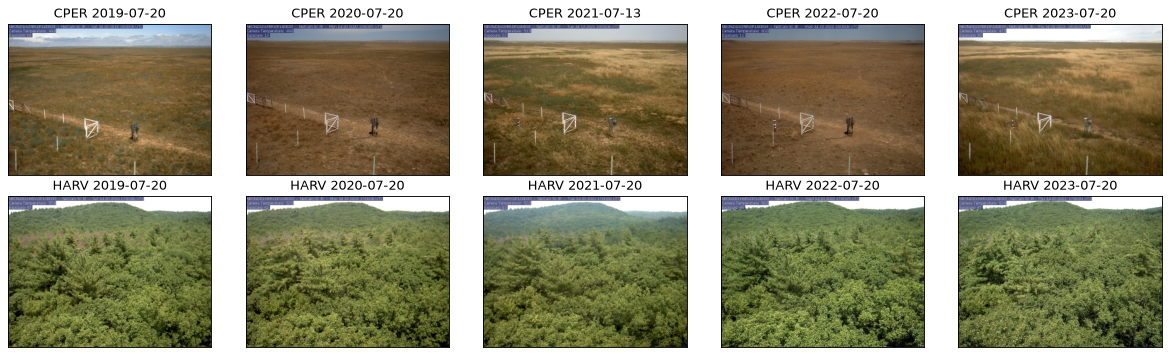

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(15, 4.5))
for ax, ((site, year), g) in zip(axes.ravel(), S.groupby(['site', 'year'])):
    ax.imshow(Image.open(g.jpg.iloc[len(g) // 2]).reduce(4))
    ax.set(title=f'{site} {g.date.iloc[len(g) // 2]:%Y-%m-%d}', xticks=[], yticks=[])
fig.tight_layout()

### PhenoCam ROI mask history

The PhenoCam team redraws a region-of-interest mask when the field of view shifts, so each new mask marks a change of view.

In [10]:
def roi_history(site, roi):
    cam = SITES[site]
    f = META / f'{cam}_{roi}_roi.csv'
    if not f.exists(): f.write_text(requests.get(f'{neon.PHENO}/data/archive/{cam}/ROI/{cam}_{roi}_roi.csv', timeout=60).text, encoding='utf-8')
    return pd.read_csv(f, comment='#').assign(site=site, roi=roi)[['site', 'roi', 'start_date', 'end_date', 'maskfile']]

pd.concat([roi_history('HARV', r) for r in ['DB_1000', 'DB_2000', 'EN_1000', 'EN_2000', 'EN_3000']] + [roi_history('CPER', 'GR_1000')], ignore_index=True)

,site,roi,start_date,end_date,maskfile
0,HARV,DB_1000,2016-12-13,2025-09-29,NEON.D01.HARV.DP1.00033_DB_1000_01.tif
1,HARV,DB_2000,2025-9-30,9999-12-31,NEON.D01.HARV.DP1.00033_DB_2000_01.tif
2,HARV,EN_1000,2016-12-13,2022-01-07,NEON.D01.HARV.DP1.00033_EN_1000_01.tif
3,HARV,EN_2000,2022-02-15,2022-03-20,NEON.D01.HARV.DP1.00033_EN_2000_01.tif
4,HARV,EN_2000,2022-03-21,2025-09-29,NEON.D01.HARV.DP1.00033_EN_2000_02.tif
5,HARV,EN_3000,2025-09-30,9999-12-31,NEON.D01.HARV.DP1.00033_EN_3000_01.tif
6,CPER,GR_1000,2016-12-10,9999-12-31,NEON.D10.CPER.DP1.00033_GR_1000_01.tif


**Reading.**

| question | HARV | CPER |
|---|---|---|
| all five products published for June–August 2019–2023 | yes | yes |
| site-specific instrument log entries in a summer | none for the label, conditioning or radiation sensors (the wind logs concern the lower booms ML3/ML4, not the tower-top 000.050 used) | none (radiometer out of level November 2020 – February 2021, outside the summers) |
| tower-top levels and sensor positions | unchanged for RH, TRAAT and SLRNR; wind boom record re-dated 2021-09-26 (z 29.58 → 28.91 m) | unchanged |
| July label quality (valid share) | ≥ 0.94 except **2021: 0.75** (RH up to 558 %, a sensor fault) | ≥ 0.98 except **2019: 0.58** |
| radiation error, high sun and calm (probe − PRT) | 0.6–1.2 K, but **0.12 K in 2022** | 1.2–1.7 K every year |
| HMP155 expanded RH uncertainty (median) | 1.3–2.3 % by year | 1.2–3.1 % by year |
| camera unit (MAC) | **replaced between July 2021 and July 2022** | same unit 2019–2023 |
| camera configuration (`.meta`) | identical in every sampled frame (auto-haze, AGC, auto-exposure, exposure limit, white balance, resolution, JPEG quality, sharpen, saturation, contrast, brightness) | identical |
| view against 2023 | no translation found, but edge correlation 0.36–0.37 in 2019–2021 against 0.50 (2022) and 0.68 (2023). The evergreen ROI masks were redrawn in February–March 2022 | **2019 view differs** (horizon, gate and scale; phase correlation 44 px vertical, edge correlation 0.33); 2020–2023 consistent (0.66–0.84) |
| midday frames, days of 92 | 92 every summer | 92, except 89 in 2021 |

Network-wide entries that touch every year in scope:
- COVID-19 reduced maintenance and delayed the annual sensor refresh from March 2020 to December 2021, so summers 2020 and 2021 carry older calibrations.
- The flow-test QC of the aspirated shield was changed and reprocessed (RELEASE-2024 on).
- The radiometer calibration interval was lengthened from one to two years in March 2022.

**Consequences for the multi-year extension (exploratory, no download decided here).**
- **CPER 2020–2023** is the most homogeneous block: same camera unit, configuration and view, stable sensor positions, label valid ≥ 0.98. That gives 4 summers and leave-one-summer-out folds.
- **CPER 2019** needs its own image regions, or must be excluded, and its July label is only 58 % valid.
- **HARV** has a camera-unit replacement and a view change between 2021 and 2022. Those are camera changes in exactly the sense of the notebook 11 camera world. Two coherent blocks exist, 2019–2021 and 2022–2023; pooling them requires a declared camera-epoch stratum (the shift test within epochs, and an epoch indicator in V's null generator).
- HARV July 2021 has a label fault period.
- HARV 2022's near-zero radiation error at high sun differs from every other year. Until it is explained (a shield or probe change, cleaning, or a different radiation regime), D_probe sensitivities cannot be pooled across years.
- The fixed image bands of `features.py` were set on 2023 frames. They must be re-checked against each epoch's reference frame before features are extracted from another epoch.
- Calibration cannot be audited from the basic package beyond these uncertainty summaries. Individual sensor swaps for RH and TRAAT are not in the public logs; the expanded package's calibration flags would be the next step for any year that is used.

Downloaded for this audit: 228 MB of tower data (one July per site and year) and 139 midday frames with `.meta`.